# Лабораторная работа № 1 — Первичная обработка одномерной выборки

**Вариант № 14 · ПИН-27 · Python**

**Примечание:** исходная выборка и ранее проверенные числовые результаты оставлены без изменений. Пункты 1–5 выполняются последовательно и независимо. Красным отмечены исправленные места.

<span style="color:#b91c1c">**ИСПРАВЛЕНО:** восемь столбцов таблицы, полигоны на обеих гистограммах, ЭФР без вертикальных линий и с открытыми/закрашенными концами, выведены S и S_гр.</span>

## 1. Вариационный и статистический ряды

Полный вариационный ряд и контроль частот без изменения исходных данных.

In [1]:

import numpy as np

# Лабораторная работа № 1
# Вариант № 14
# Задание 1. Вариационный и статистический ряды

# Исходная выборка из 50 наблюдений
x = np.array([
    2.97, 20.12, 15.15, 1.11, 12.54,
    14.98, 5.62, 2.49, 4.15, 18.84,
    9.53, 25.79, 5.03, 0.16, 0.22,
    7.31, 21.76, 2.83, 6.86, 26.18,
    1.23, 10.81, -3.25, 0.46, 5.27,
    1.53, -3.21, 10.61, 19.22, 10.09,
    6.53, 5.28, 1.60, 10.77, 11.99,
    19.67, 13.56, 7.65, -9.70, 27.12,
    3.39, 10.35, 17.09, -3.50, 13.25,
    10.33, 11.02, 4.65, 23.90, 8.77
], dtype=float)

# Определяем объём выборки
n = len(x)

# Строим вариационный ряд по неубыванию
ordered = np.sort(x)

# Определяем различные значения и их частоты
values, frequencies = np.unique(
    ordered, return_counts=True
)

# Вычисляем относительные частоты: w_i = n_i / n
weights = frequencies / n

print("Задание 1. Вариационный ряд")
print("Объём выборки:", n)

for i, value in enumerate(ordered, 1):
    print(f"x_({i}) = {value:.2f}")

# Выводим полный статистический ряд
print("\nСтатистический ряд")
print(
    f'{"Номер":>6} {"Значение":>12} '
    f'{"Частота":>10} {"Относительная частота":>24}'
)

for i, (value, frequency, weight) in enumerate(
    zip(values, frequencies, weights), 1
):
    print(
        f"{i:6d} {value:12.2f} "
        f"{frequency:10d} {weight:24.2f}"
    )

# Вычисляем минимальное и максимальное значения
xmin = ordered[0]
xmax = ordered[-1]

# Размах выборки: R = xmax - xmin
R = xmax - xmin

print("\nЧисловые результаты")
print(f"Минимальное значение = {xmin:.2f}")
print(f"Максимальное значение = {xmax:.2f}")
print(f"Размах выборки = {xmax:.2f} - ({xmin:.2f})")
print(f"Размах выборки = {R:.2f}")

# Проверяем основные свойства статистического ряда
print("\nПроверка результатов")
print(f"Сумма частот = {frequencies.sum()}")
print(f"Сумма относительных частот = {weights.sum():.6f}")

assert n == 50
assert len(values) == 50
assert np.all(frequencies == 1)
assert frequencies.sum() == n
assert np.isclose(weights.sum(), 1.0)
assert np.isclose(R, 36.82)

print("Все проверки выполнены успешно.")


Задание 1. Вариационный ряд
Объём выборки: 50
x_(1) = -9.70
x_(2) = -3.50
x_(3) = -3.25
x_(4) = -3.21
x_(5) = 0.16
x_(6) = 0.22
x_(7) = 0.46
x_(8) = 1.11
x_(9) = 1.23
x_(10) = 1.53
x_(11) = 1.60
x_(12) = 2.49
x_(13) = 2.83
x_(14) = 2.97
x_(15) = 3.39
x_(16) = 4.15
x_(17) = 4.65
x_(18) = 5.03
x_(19) = 5.27
x_(20) = 5.28
x_(21) = 5.62
x_(22) = 6.53
x_(23) = 6.86
x_(24) = 7.31
x_(25) = 7.65
x_(26) = 8.77
x_(27) = 9.53
x_(28) = 10.09
x_(29) = 10.33
x_(30) = 10.35
x_(31) = 10.61
x_(32) = 10.77
x_(33) = 10.81
x_(34) = 11.02
x_(35) = 11.99
x_(36) = 12.54
x_(37) = 13.25
x_(38) = 13.56
x_(39) = 14.98
x_(40) = 15.15
x_(41) = 17.09
x_(42) = 18.84
x_(43) = 19.22
x_(44) = 19.67
x_(45) = 20.12
x_(46) = 21.76
x_(47) = 23.90
x_(48) = 25.79
x_(49) = 26.18
x_(50) = 27.12

Статистический ряд
 Номер     Значение    Частота    Относительная частота
     1        -9.70          1                     0.02
     2        -3.50          1                     0.02
     3        -3.25          1                  

## 2. Интервальный статистический ряд

<span style="color:#b91c1c">**ИСПРАВЛЕНО:** таблица строго из 8 столбцов; удалён лишний столбец абсолютной накопленной частоты. Заголовки написаны полностью по-русски.</span>

In [2]:
import numpy as np

# Лабораторная работа № 1
# Вариант № 14
# Задание 2. Интервальный статистический ряд

# Исходные данные
x = np.array([
    2.97, 20.12, 15.15, 1.11, 12.54,
    14.98, 5.62, 2.49, 4.15, 18.84,
    9.53, 25.79, 5.03, 0.16, 0.22,
    7.31, 21.76, 2.83, 6.86, 26.18,
    1.23, 10.81, -3.25, 0.46, 5.27,
    1.53, -3.21, 10.61, 19.22, 10.09,
    6.53, 5.28, 1.60, 10.77, 11.99,
    19.67, 13.56, 7.65, -9.70, 27.12,
    3.39, 10.35, 17.09, -3.50, 13.25,
    10.33, 11.02, 4.65, 23.90, 8.77
], dtype=float)

# Объём выборки и число интервалов
n = len(x)
k = 7

# Минимальное и максимальное значения
xmin = np.min(x)
xmax = np.max(x)

# Вычисляем размах выборки
R = xmax - xmin

# Ширина равных интервалов: delta = R / k
delta = R / k

# Формируем границы семи равных интервалов
edges = np.linspace(xmin, xmax, k + 1)

# Вычисляем середины интервалов
# z_j = (a_(j-1) + a_j) / 2
centers = (edges[:-1] + edges[1:]) / 2

# Подсчитываем частоты наблюдений в интервалах
# Левые границы включаются, правые не включаются
# Правая граница последнего интервала включается
counts, _ = np.histogram(x, bins=edges)

# Относительные частоты: w_j = n_j / n
weights = counts / n

# Накопленные частоты: N_j = сумма n_i
cum_counts = np.cumsum(counts)

# Накопленные относительные частоты
cum_weights = np.cumsum(weights)

# Высоты гистограммы частот: h_j = n_j / delta
heights = counts / delta

# Высоты гистограммы относительных частот
# f_j = n_j / (n * delta)
relative_heights = counts / (n * delta)

print("Задание 2. Интервальный статистический ряд")
print(f"Объём выборки = {n}")
print(f"Число интервалов = {k}")
print(f"Размах выборки = {R:.6f}")
print(f"Ширина интервала = {delta:.6f}")

# Выводим таблицу границ и середин интервалов
print("\nГраницы интервалов")

for j, edge in enumerate(edges):
    print(f"a_{j} = {edge:.2f}")

print("\nСередины интервалов")

for j, center in enumerate(centers, 1):
    print(f"z_{j} = {center:.2f}")

# ИСПРАВЛЕНО: таблица Жарковой содержит РОВНО 8 столбцов.
# Абсолютные накопленные частоты не выводятся в эту таблицу.
# Все заголовки записываем полностью, без сокращений.
import pandas as pd

intervals = []
for j in range(k):
    end_bracket = "]" if j == k - 1 else ")"
    intervals.append(
        f"[{edges[j]:.2f}; {edges[j+1]:.2f}{end_bracket}"
    )

table = pd.DataFrame({
    "Номер разряда": np.arange(1, k + 1),
    "Разряд": intervals,
    "Середина разряда": centers,
    "Частота": counts,
    "Относительная частота": weights,
    "Относительная накопленная частота": cum_weights,
    "Высота гистограммы частот": heights,
    "Высота гистограммы относительных частот": relative_heights,
})

print("\nТаблица из восьми столбцов (требование Жарковой):")
with pd.option_context("display.max_columns", None, "display.width", 240,
                       "display.float_format", "{:.6f}".format):
    print(table.to_string(index=False))
print(f"\nЧастоты по разрядам: {counts.tolist()}")
print(f"Накопленные относительные частоты: {cum_weights.tolist()}")
assert table.shape == (7, 8)
assert "Накопленная частота" not in table.columns

# Проверяем сумму частот
sum_counts = np.sum(counts)
sum_weights = np.sum(weights)

# Проверяем суммы площадей прямоугольников
area_counts = np.sum(heights * delta)
area_relative = np.sum(relative_heights * delta)

print("\nПроверка результатов")
print(f"Сумма частот = {sum_counts}")
print(f"Сумма относительных частот = {sum_weights:.6f}")
print(f"Площадь гистограммы частот = {area_counts:.6f}")
print(f"Площадь гистограммы относительных частот = {area_relative:.6f}")

assert counts.tolist() == [1, 6, 14, 13, 6, 6, 4]
assert np.isclose(delta, 5.26)
assert sum_counts == n
assert np.isclose(sum_weights, 1.0)
assert np.isclose(area_counts, n)
assert np.isclose(area_relative, 1.0)

print("Все проверки выполнены успешно.")


Задание 2. Интервальный статистический ряд
Объём выборки = 50
Число интервалов = 7
Размах выборки = 36.820000
Ширина интервала = 5.260000

Границы интервалов
a_0 = -9.70
a_1 = -4.44
a_2 = 0.82
a_3 = 6.08
a_4 = 11.34
a_5 = 16.60
a_6 = 21.86
a_7 = 27.12

Середины интервалов
z_1 = -7.07
z_2 = -1.81
z_3 = 3.45
z_4 = 8.71
z_5 = 13.97
z_6 = 19.23
z_7 = 24.49

Таблица из восьми столбцов (требование Жарковой):
 Номер разряда         Разряд  Середина разряда  Частота  Относительная частота  Относительная накопленная частота  Высота гистограммы частот  Высота гистограммы относительных частот
             1 [-9.70; -4.44)         -7.070000        1               0.020000                           0.020000                   0.190114                                 0.003802
             2  [-4.44; 0.82)         -1.810000        6               0.120000                           0.140000                   1.140684                                 0.022814
             3   [0.82; 6.08)          3.4500

## 3. Гистограммы и полигоны

<span style="color:#b91c1c">**ИСПРАВЛЕНО:** два полигона наложены на соответствующие гистограммы, гладкая кривая плотности отсутствует.</span>

Задание 3. Проверка построения двух полигонов
Площадь гистограммы частот = 50.000000
Площадь гистограммы относительных частот = 1.000000
Все проверки выполнены успешно.


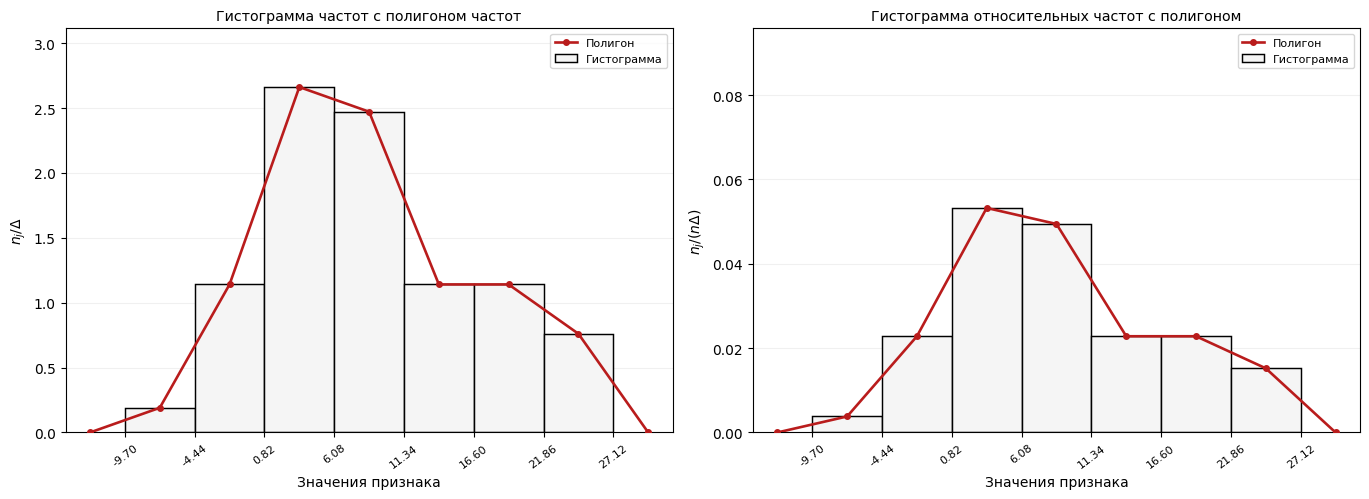

In [3]:

import numpy as np
import matplotlib.pyplot as plt

# Лабораторная работа № 1
# Вариант № 14
# Задание 3. Построение гистограмм и полигона

# Исходные данные
x = np.array([
    2.97, 20.12, 15.15, 1.11, 12.54,
    14.98, 5.62, 2.49, 4.15, 18.84,
    9.53, 25.79, 5.03, 0.16, 0.22,
    7.31, 21.76, 2.83, 6.86, 26.18,
    1.23, 10.81, -3.25, 0.46, 5.27,
    1.53, -3.21, 10.61, 19.22, 10.09,
    6.53, 5.28, 1.60, 10.77, 11.99,
    19.67, 13.56, 7.65, -9.70, 27.12,
    3.39, 10.35, 17.09, -3.50, 13.25,
    10.33, 11.02, 4.65, 23.90, 8.77
], dtype=float)

# Настройка отображения русского текста
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

n = len(x)
k = 7

# Определяем границы интервалов
edges = np.linspace(np.min(x), np.max(x), k + 1)

# Ширина равных интервалов
delta = edges[1] - edges[0]

# Середины интервалов
centers = (edges[:-1] + edges[1:]) / 2

# Частоты в каждом интервале
counts, _ = np.histogram(x, bins=edges)

# Высоты гистограммы частот
# h_j = n_j / delta
heights = counts / delta

# Высоты гистограммы относительных частот
# f_j = n_j / (n * delta)
relative_heights = counts / (n * delta)

# ------------------------------------------------
# ИСПРАВЛЕНО: полигон поверх КАЖДОЙ гистограммы.
# Левая гистограмма: n_j/Δ. Правая: n_j/(nΔ).
# Гладкую теоретическую кривую НЕ строим.
# ------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13.8, 5.1))

for ax, vals, title, ylabel in (
    (axes[0], heights, "Гистограмма частот с полигоном частот", r"$n_j/\Delta$"),
    (axes[1], relative_heights, "Гистограмма относительных частот с полигоном", r"$n_j/(n\Delta)$"),
):
    # Столбцы гистограммы с заданными высотами.
    ax.bar(edges[:-1], vals, width=delta, align="edge", color="#f5f5f5",
           edgecolor="black", linewidth=1.05, label="Гистограмма", zorder=2)
    # Полигон соединяет середины верхних оснований прямоугольников.
    # За пределами крайних разрядов добавлены нулевые вершины.
    poly_x = np.r_[centers[0]-delta, centers, centers[-1]+delta]
    poly_y = np.r_[0, vals, 0]
    ax.plot(poly_x, poly_y, "o-", color="#b91c1c", lw=1.9, ms=4,
            label="Полигон", zorder=4)
    ax.set_title(title, fontsize=10.3)
    ax.set_xlabel("Значения признака")
    ax.set_ylabel(ylabel)
    ax.set_xlim(edges[0]-delta*0.85,edges[-1]+delta*0.85)
    ax.set_xticks(edges)
    ax.tick_params(axis="x",labelrotation=37,labelsize=8)
    ax.grid(axis="y",alpha=0.19,zorder=0)
    ax.legend(fontsize=8,loc="upper right")

# По замечанию Жарковой правая гистограмма визуально ниже левой.
axes[0].set_ylim(0, max(heights)*1.17)
axes[1].set_ylim(0, max(relative_heights)*1.80)
fig.tight_layout()
fig.savefig("Lab1_Histograms_with_BOTH_Polygons.png",dpi=220,bbox_inches="tight")

# Контроль площадей гистограмм.
area_1 = np.sum(heights*delta)
area_2 = np.sum(relative_heights*delta)
print("Задание 3. Проверка построения двух полигонов")
print(f"Площадь гистограммы частот = {area_1:.6f}")
print(f"Площадь гистограммы относительных частот = {area_2:.6f}")
assert np.array_equal(counts, [1,6,14,13,6,6,4])
assert np.allclose(heights, counts/delta)
assert np.allclose(relative_heights, counts/(n*delta))
assert np.isclose(area_1,n) and np.isclose(area_2,1)
print("Все проверки выполнены успешно.")
plt.show()


## 4. Эмпирические функции распределения

<span style="color:#b91c1c">**ИСПРАВЛЕНО:** отдельные горизонтальные ступени; открытый левый и закрашенный правый конец на каждом внутреннем отрезке; ни одной вертикальной линии. Вручную запрограммирована левая непрерывность, без встроенной ECDF и plt.step().</span>


Группированная эмпирическая функция распределения:
  0, если x <= -7.07
  1/50 = 0.02, если -7.07 < x <= -1.81
  7/50 = 0.14, если -1.81 < x <= 3.45
  21/50 = 0.42, если 3.45 < x <= 8.71
  34/50 = 0.68, если 8.71 < x <= 13.97
  40/50 = 0.80, если 13.97 < x <= 19.23
  46/50 = 0.92, если 19.23 < x <= 24.49
  1, если x > 24.49

Исходная эмпирическая функция распределения:
  0, если x <= -9.70
  1/50, если -9.70 < x <= -3.50
  2/50, если -3.50 < x <= -3.25
  3/50, если -3.25 < x <= -3.21
  4/50, если -3.21 < x <= 0.16
  5/50, если 0.16 < x <= 0.22
  6/50, если 0.22 < x <= 0.46
  7/50, если 0.46 < x <= 1.11
  8/50, если 1.11 < x <= 1.23
  9/50, если 1.23 < x <= 1.53
  10/50, если 1.53 < x <= 1.60
  11/50, если 1.60 < x <= 2.49
  12/50, если 2.49 < x <= 2.83
  13/50, если 2.83 < x <= 2.97
  14/50, если 2.97 < x <= 3.39
  15/50, если 3.39 < x <= 4.15
  16/50, если 4.15 < x <= 4.65
  17/50, если 4.65 < x <= 5.03
  18/50, если 5.03 < x <= 5.27
  19/50, если 5.27 < x <= 5.28
  20/50, если 5.28 

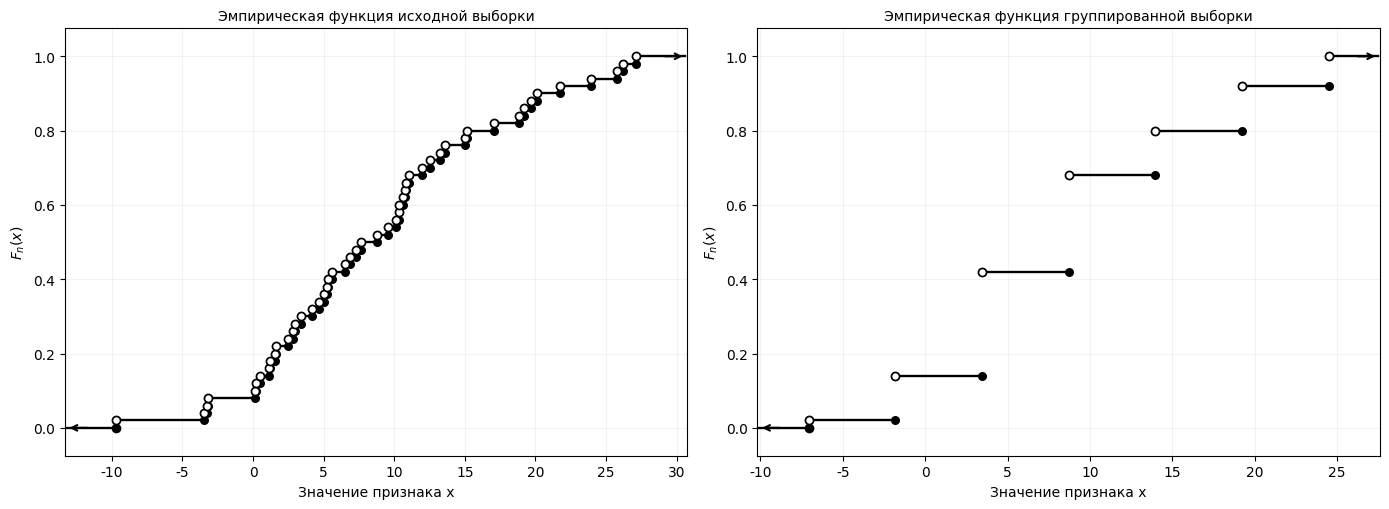

In [4]:

import numpy as np
import matplotlib.pyplot as plt

# Лабораторная работа № 1
# Вариант № 14
# Задание 4. Эмпирические функции распределения

# Исходные данные
x = np.array([
    2.97, 20.12, 15.15, 1.11, 12.54,
    14.98, 5.62, 2.49, 4.15, 18.84,
    9.53, 25.79, 5.03, 0.16, 0.22,
    7.31, 21.76, 2.83, 6.86, 26.18,
    1.23, 10.81, -3.25, 0.46, 5.27,
    1.53, -3.21, 10.61, 19.22, 10.09,
    6.53, 5.28, 1.60, 10.77, 11.99,
    19.67, 13.56, 7.65, -9.70, 27.12,
    3.39, 10.35, 17.09, -3.50, 13.25,
    10.33, 11.02, 4.65, 23.90, 8.77
], dtype=float)

# Настройка русского текста на графиках
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

n = len(x)
k = 7

# Упорядочиваем исходную выборку
ordered = np.sort(x)

# Границы семи интервалов
edges = np.linspace(ordered[0], ordered[-1], k + 1)

# Ширина интервала
delta = edges[1] - edges[0]

# Середины интервалов и их частоты
centers = (edges[:-1] + edges[1:]) / 2
counts, _ = np.histogram(x, bins=edges)

# ------------------------------------------------
# ИСПРАВЛЕНО: рисуем ступеньки вручную, без вертикальных линий.
# Левосторонняя непрерывность: F_n(x) = #{x_i < x}/n.
# Слева от каждого скачка — пустая точка ○ на верхней ступени,
# справа на предыдущем уровне — закрашенная точка ●.
# Не используем plt.step() и встроенные функции ECDF.
# ------------------------------------------------

def draw_left_continuous_cdf(ax, values, multiplicities, title):
    """Рисует только горизонтальные отрезки, ○ и ●; вертикалей нет."""
    vals = np.asarray(values,dtype=float)
    counts_local=np.asarray(multiplicities,dtype=int)
    total=int(counts_local.sum())
    pad=max(1.6,(vals[-1]-vals[0])*0.095)
    llim=vals[0]-pad; rlim=vals[-1]+pad
    cumulative=np.cumsum(counts_local)/total

    # F(x)=0 при x <= z_1; правая точка закрашена.
    ax.plot([llim,vals[0]],[0,0],color="black",lw=1.7,zorder=3)
    ax.scatter([vals[0]],[0],s=36,c="black",zorder=6)
    ax.annotate("",xy=(llim,0),xytext=(llim+pad*0.47,0),
                arrowprops={"arrowstyle":"->","lw":1.5,"color":"black"})

    # На каждой ступеньке (z_i;z_(i+1)] уровень F_i.
    for j in range(len(vals)-1):
        y=float(cumulative[j])
        ax.plot([vals[j],vals[j+1]],[y,y],color="black",lw=1.7,zorder=3)
        # В левой точке (z_i,y) значение F не достигается.
        ax.scatter([vals[j]],[y],s=34,facecolors="white",
                   edgecolors="black",linewidth=1.25,zorder=7)
        # В правой точке (z_(i+1),y) значение достигается.
        ax.scatter([vals[j+1]],[y],s=30,c="black",zorder=6)

    # На правом луче (z_last;+inf) F(x)=1; точка у z_last пуста.
    ax.plot([vals[-1],rlim],[1,1],color="black",lw=1.7,zorder=3)
    ax.scatter([vals[-1]],[1],s=34,facecolors="white",
               edgecolors="black",linewidth=1.25,zorder=7)
    ax.annotate("",xy=(rlim,1),xytext=(rlim-pad*0.47,1),
                arrowprops={"arrowstyle":"->","lw":1.5,"color":"black"})
    ax.set_xlim(llim-pad*.04,rlim+pad*.04)
    ax.set_ylim(-0.075,1.075)
    ax.set_xlabel("Значение признака x")
    ax.set_ylabel(r"$F_n(x)$")
    ax.set_title(title,fontsize=10)
    ax.set_yticks(np.linspace(0,1,6))
    ax.grid(alpha=0.16,zorder=0)
    # Проверка: все построенные линии горизонтальны.
    for line in ax.lines:
        yy=np.asarray(line.get_ydata(),dtype=float)
        assert np.ptp(yy) < 1e-12, "Найдена вертикальная линия!"

fig,axes=plt.subplots(1,2,figsize=(14,5.2))
draw_left_continuous_cdf(
    axes[0], ordered, np.ones(n,dtype=int),
    "Эмпирическая функция исходной выборки"
)
draw_left_continuous_cdf(
    axes[1], centers, counts,
    "Эмпирическая функция группированной выборки"
)
fig.tight_layout()
fig.savefig("Lab1_ECDF_no_verticals_open_left_closed_right.png",
            dpi=220,bbox_inches="tight")

# Печатаем строгую кусочную формулу сгруппированной функции (8 строк).
# Каждое значение z_j относится к предыдущей (нижней) ступени.
print("\nГруппированная эмпирическая функция распределения:")
print(f"  0, если x <= {centers[0]:.2f}")
for j in range(k-1):
    print(f"  {np.cumsum(counts)[j]}/50 = {np.cumsum(counts)[j]/n:.2f}, "
          f"если {centers[j]:.2f} < x <= {centers[j+1]:.2f}")
print(f"  1, если x > {centers[-1]:.2f}")

# Печатаем полную кусочную формулу исходной функции (51 случай).
print("\nИсходная эмпирическая функция распределения:")
print(f"  0, если x <= {ordered[0]:.2f}")
for j in range(n-1):
    print(f"  {j+1}/50, если {ordered[j]:.2f} < x <= {ordered[j+1]:.2f}")
print(f"  1, если x > {ordered[-1]:.2f}")

# Контроль точек скачков для левостороннего варианта.
for v in ordered:
    assert np.isclose(np.sum(x < v)/n, np.searchsorted(ordered,v,side="left")/n)
for j,z in enumerate(centers):
    assert np.isclose(np.sum(counts[centers < z])/n,
                      (np.sum(counts[:j])/n))
print("\nВсе проверки выполнены успешно: вертикальных линий нет.")
plt.show()


## 5. Выборочные числовые характеристики

<span style="color:#b91c1c">**ДОПОЛНЕНО:** среднеквадратические отклонения S и S_гр; все ранее верные средние, дисперсии и необходимые вычисления сохранены.</span>

In [5]:

import numpy as np

# Лабораторная работа № 1
# Вариант № 14
# Задание 5. Выборочные числовые характеристики

# Исходная выборка
x = np.array([
    2.97, 20.12, 15.15, 1.11, 12.54,
    14.98, 5.62, 2.49, 4.15, 18.84,
    9.53, 25.79, 5.03, 0.16, 0.22,
    7.31, 21.76, 2.83, 6.86, 26.18,
    1.23, 10.81, -3.25, 0.46, 5.27,
    1.53, -3.21, 10.61, 19.22, 10.09,
    6.53, 5.28, 1.60, 10.77, 11.99,
    19.67, 13.56, 7.65, -9.70, 27.12,
    3.39, 10.35, 17.09, -3.50, 13.25,
    10.33, 11.02, 4.65, 23.90, 8.77
], dtype=float)

n = len(x)
k = 7

# ------------------------------------------------
# Числовые характеристики исходной выборки
# ------------------------------------------------

# Упорядочиваем наблюдения для определения медианы
ordered = np.sort(x)

# Вычисляем сумму наблюдений
sum_x = np.sum(x)

# Вычисляем сумму квадратов наблюдений
sum_x2 = np.sum(x ** 2)

# Выборочное среднее: x_bar = сумма x_i / n
mean = sum_x / n

# Сумма квадратов отклонений от среднего
# Q = сумма x_i^2 - n * x_bar^2
Q = sum_x2 - n * mean ** 2

# Выборочная дисперсия с делителем n
variance = Q / n

# Исправленная выборочная дисперсия
# S^2 = Q / (n - 1)
corrected_variance = Q / (n - 1)

# Исправленное среднеквадратическое отклонение: S = sqrt(S^2)
standard_deviation = np.sqrt(corrected_variance)

# Медиана при чётном объёме выборки
# Me = (x_(25) + x_(26)) / 2
median = (
    ordered[n // 2 - 1] + ordered[n // 2]
) / 2

# Проверяем наличие единственной моды
values, frequencies = np.unique(
    x, return_counts=True
)

print("Задание 5. Выборочные характеристики")
print("\nНегруппированная выборка")

print(f"Объём выборки = {n}")
print(f"Сумма наблюдений = {sum_x:.6f}")
print(f"Сумма квадратов = {sum_x2:.6f}")

print(
    f"Выборочное среднее: "
    f"{sum_x:.6f} / {n} = {mean:.6f}"
)

print(
    f"Сумма квадратов отклонений: "
    f"{sum_x2:.6f} - {n} * ({mean:.6f})^2 "
    f"= {Q:.6f}"
)

print(
    f"Выборочная дисперсия: "
    f"{Q:.6f} / {n} = {variance:.6f}"
)

print(
    f"Исправленная дисперсия: "
    f"{Q:.6f} / {n - 1} "
    f"= {corrected_variance:.6f}"
)

print(
    f"Медиана: ({ordered[24]:.2f} + "
    f"{ordered[25]:.2f}) / 2 = {median:.6f}"
)

if np.all(frequencies == 1):
    print("Единственная мода отсутствует.")
else:
    max_frequency = np.max(frequencies)
    modes = values[frequencies == max_frequency]
    print("Значения с максимальной частотой:", modes)

# ------------------------------------------------
# Числовые характеристики группированной выборки
# ------------------------------------------------

# Делим размах выборки на семь равных интервалов
edges = np.linspace(np.min(x), np.max(x), k + 1)

# Ширина интервала
delta = edges[1] - edges[0]

# Середины интервалов
centers = (edges[:-1] + edges[1:]) / 2

# Частоты наблюдений
counts, _ = np.histogram(x, bins=edges)

# Накопленные частоты
cum_counts = np.cumsum(counts)

# Сумма произведений частот на середины
sum_nz = np.sum(counts * centers)

# Сумма произведений частот на квадраты середин
sum_nz2 = np.sum(counts * centers ** 2)

# Выборочное среднее группированной выборки
mean_group = sum_nz / n

# Сумма квадратов отклонений группированной выборки
Q_group = sum_nz2 - n * mean_group ** 2

# Выборочная дисперсия группированной выборки
variance_group = Q_group / n

# Исправленная дисперсия группированной выборки
corrected_group = Q_group / (n - 1)

# Исправленное среднеквадратическое отклонение группировки
standard_deviation_group = np.sqrt(corrected_group)

# ------------------------------------------------
# Медиана группированной выборки
# ------------------------------------------------

# Определяем медианный интервал
median_index = np.searchsorted(
    cum_counts, n / 2
)

# Частота перед медианным интервалом
previous_count = (
    cum_counts[median_index - 1]
    if median_index > 0 else 0
)

# Формула интервальной медианы
median_group = (
    edges[median_index]
    + (n / 2 - previous_count)
    / counts[median_index] * delta
)

# ------------------------------------------------
# Мода группированной выборки
# ------------------------------------------------

# Определяем интервал с наибольшей частотой
mode_index = np.argmax(counts)

# Частота предыдущего интервала
previous_frequency = (
    counts[mode_index - 1]
    if mode_index > 0 else 0
)

# Частота следующего интервала
next_frequency = (
    counts[mode_index + 1]
    if mode_index < k - 1 else 0
)

# Вычисляем моду интервального ряда
mode_group = (
    edges[mode_index]
    + (counts[mode_index] - previous_frequency)
    * delta
    / (
        2 * counts[mode_index]
        - previous_frequency
        - next_frequency
    )
)

# ------------------------------------------------
# Выводим результаты группированной выборки
# ------------------------------------------------

print("\nГруппированная выборка")

print(f"Число интервалов = {k}")
print(f"Ширина интервала = {delta:.6f}")

print(
    f"Сумма произведений частот на середины "
    f"= {sum_nz:.6f}"
)

print(
    f"Сумма произведений частот на квадраты середин "
    f"= {sum_nz2:.6f}"
)

print(
    f"Выборочное среднее: "
    f"{sum_nz:.6f} / {n} = {mean_group:.6f}"
)

print(
    f"Сумма квадратов отклонений: "
    f"{sum_nz2:.6f} - {n} * ({mean_group:.6f})^2 "
    f"= {Q_group:.6f}"
)

print(
    f"Выборочная дисперсия: "
    f"{Q_group:.6f} / {n} = {variance_group:.6f}"
)

print(
    f"Исправленная дисперсия: "
    f"{Q_group:.6f} / {n - 1} "
    f"= {corrected_group:.6f}"
)

print(
    f"Медиана группированной выборки "
    f"= {median_group:.6f}"
)

print(
    f"Мода группированной выборки "
    f"= {mode_group:.6f}"
)

# ------------------------------------------------
# Контроль числовых результатов
# ------------------------------------------------

assert n == 50
assert np.isclose(sum_x, 450.12)
assert np.isclose(sum_x2, 7526.1702)

assert np.isclose(mean, 9.0024)
assert np.isclose(variance, 69.48019824)
assert np.isclose(corrected_variance, 70.8981614694)
assert np.isclose(median, 8.21)

assert counts.tolist() == [1, 6, 14, 13, 6, 6, 4]

assert np.isclose(sum_nz, 440.76)
assert np.isclose(sum_nz2, 7011.273)

assert np.isclose(mean_group, 8.8152)
assert np.isclose(variance_group, 62.51770896)
assert np.isclose(corrected_group, 63.7935805714)
assert np.isclose(median_group, 7.6984615385)
assert np.isclose(mode_group, 5.4955555556)

# ИСПРАВЛЕНО: дополнительно выводим S и S_гр (среднеквадратические отклонения).
print(f"Исправленное среднеквадратическое отклонение S = {standard_deviation:.6f}")
print(f"Исправленное среднеквадратическое отклонение S_гр = {standard_deviation_group:.6f}")
assert np.isclose(standard_deviation**2, corrected_variance)
assert np.isclose(standard_deviation_group**2, corrected_group)

print("\nВсе проверки выполнены успешно.")


Задание 5. Выборочные характеристики

Негруппированная выборка
Объём выборки = 50
Сумма наблюдений = 450.120000
Сумма квадратов = 7526.170200
Выборочное среднее: 450.120000 / 50 = 9.002400
Сумма квадратов отклонений: 7526.170200 - 50 * (9.002400)^2 = 3474.009912
Выборочная дисперсия: 3474.009912 / 50 = 69.480198
Исправленная дисперсия: 3474.009912 / 49 = 70.898161
Медиана: (7.65 + 8.77) / 2 = 8.210000
Единственная мода отсутствует.

Группированная выборка
Число интервалов = 7
Ширина интервала = 5.260000
Сумма произведений частот на середины = 440.760000
Сумма произведений частот на квадраты середин = 7011.273000
Выборочное среднее: 440.760000 / 50 = 8.815200
Сумма квадратов отклонений: 7011.273000 - 50 * (8.815200)^2 = 3125.885448
Выборочная дисперсия: 3125.885448 / 50 = 62.517709
Исправленная дисперсия: 3125.885448 / 49 = 63.793581
Медиана группированной выборки = 7.698462
Мода группированной выборки = 5.495556
Исправленное среднеквадратическое отклонение S = 8.420105
Исправленное сре

## Теория для обязательного переноса в рукописную тетрадь

<span style="color:#b91c1c">**ДОПОЛНИТЬ ОТ РУКИ.** Это справочная запись в Python; преподаватель требует теорию и вычисления также в тетради.</span>

### Основные определения

- **Генеральная совокупность:** множество всех возможных значений исследуемого признака; случайная величина **X**.
- **Случайная выборка:** независимые одинаково распределённые случайные величины **X₁, …, Xₙ**. **Реализация:** конкретные числа **x₁, …, xₙ**.
- **Выборочный метод:** заключения о генеральной совокупности по случайной выборке.
- **Вариационный ряд:** x₍₁₎ ≤ ⋯ ≤ x₍ₙ₎. **Статистический ряд:** значения zⱼ, частоты nⱼ и относительные частоты nⱼ/n.
- **Точечная оценка:** статистика, дающая одно число для оценки неизвестного параметра.

### Четыре положения, обосновывающие выборочный метод

<span style="color:#b91c1c">**1. Теорема Гливенко.**</span> При n → ∞ эмпирическая функция распределения равномерно сходится к теоретической:  
**P{supₓ |Fₙ(x) − F(x)| < ε} → 1** при любом ε > 0.

<span style="color:#b91c1c">**2. Дискретная СВ.**</span> Относительная частота значения zⱼ сходится к его вероятности:  
**nⱼ/n → P{X = zⱼ}**.

<span style="color:#b91c1c">**3. Непрерывная СВ.**</span> Относительная частота попадания в разряд Δⱼ сходится к вероятности разряда:  
**nⱼ/n → P{X ∈ Δⱼ}**.

<span style="color:#b91c1c">**4. Гистограмма и плотность.**</span> Гистограммная оценка плотности **pₙ,Δ(x) → fₓ(x)** при n → ∞, Δ → 0 при стандартных условиях согласованности (в частности, nΔ → ∞).

### Три свойства точечной оценки

<span style="color:#b91c1c">**Несмещённость:**</span> M(θ̂ₙ) = θ.  
<span style="color:#b91c1c">**Состоятельность:**</span> θ̂ₙ → θ по вероятности. Достаточное условие: M(θ̂ₙ)=θ и D(θ̂ₙ)→0. По неравенству Чебышёва P{|θ̂ₙ−θ| ≥ ε} ≤ D(θ̂ₙ)/ε² → 0.  
<span style="color:#b91c1c">**Эффективность:**</span> наименьшая дисперсия среди рассматриваемых несмещённых оценок.

<span style="color:#b91c1c">**Важно:** доверительные интервалы относятся к лабораторной работе № 2, а не № 1.</span>